# GPT traductor español → inglés

GPT propio (solo decoder) construido desde cero siguiendo [minGPT](https://github.com/karpathy/minGPT), entrenado con la mezcla de **spa-eng** (frases cotidianas de Tatoeba / manythings.org) y una parte limpia de **OPUS-100 en-es** (subtítulos, documentos y textos técnicos). Cada ejemplo se escribe como una sola secuencia y el modelo aprende a completar la parte en inglés:

`<es> ¿Dónde está la estación? <en> Where is the station? <eos>`

**Configuración de la sesión de Kaggle**
- Accelerator: **GPU T4 x2**
- Internet: **activado** (descarga de OPUS-100 desde Hugging Face y, si faltan, instalación de `datasets` y `sacrebleu`)
- Input: el zip de **spa-eng** subido como dataset (el notebook busca `spa.txt` dentro de `/kaggle/input`)

**Flujo:** 1. Setup → 2. Análisis de datos → 3. Tokenizador y dataset → 4. Modelo → 5. Trainer → 6. ¿1 o 2 GPUs? → 7. Entrenamiento → 8. Métricas → 9. Testing

## 1. Setup

In [45]:
import importlib.util
import subprocess
import sys

for package in ("datasets", "sacrebleu"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [46]:
import copy
import csv
import math
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import torch
import torch.nn as nn
from datasets import load_dataset
from matplotlib.ticker import MaxNLocator
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset

SEED = 1337
DATA_PATH = next(Path("/kaggle/input").rglob("spa.txt"))
WORK_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
})
pd.set_option("display.max_colwidth", 100)

print("dataset:", DATA_PATH)
print("torch:", torch.__version__, "| GPUs:", N_GPUS)
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i} {props.name} | {props.total_memory / 1e9:.1f} GB")

dataset: /kaggle/input/datasets/iesusdavila/spa-en/spa.txt
torch: 2.11.0+cu128 | GPUs: 2
  cuda:0 Tesla T4 | 15.6 GB
  cuda:1 Tesla T4 | 15.6 GB


## 2. Análisis de datos

### 2.1 spa-eng (Tatoeba)

In [47]:
raw = pd.read_csv(DATA_PATH, sep="\t", names=["en", "es"], quoting=csv.QUOTE_NONE)
print(f"{len(raw):,} pares")
raw.sample(8, random_state=SEED)

118,964 pares


,en,es
14396,Thanks for asking.,Gracias por preguntarme.
35082,Do they love each other?,¿Ellos se aman?
38752,You don't have a choice.,No tienes opción.
109924,The car won't start. Will you help me push the car?,El coche no arranca. ¿Me ayudáis a empujar el coche?
1393,Tom cheats.,Tomás hace trampa.
114522,I have a feeling something very special is going to happen.,Tengo el presentimiento de que algo muy especial va a suceder.
52446,I couldn't eat another bite.,No podría comer otro bocado.
72045,He gave his life for his country.,Él dio la vida por su país.


In [48]:
words = raw.apply(lambda col: col.str.split().str.len())
translations_per_es = raw.groupby("es")["en"].count()

print(f"Pares duplicados: {raw.duplicated().sum():,}")
print(f"Frases en español con más de una traducción: {(translations_per_es > 1).sum():,} ({(translations_per_es > 1).mean():.1%})")
pd.DataFrame({
    "nulos": raw.isna().sum(),
    "frases únicas": raw.nunique(),
    "palabras (media)": words.mean().round(2),
    "palabras (p99)": words.quantile(0.99),
    "palabras (máx)": words.max(),
})

Pares duplicados: 0
Frases en español con más de una traducción: 4,825 (4.3%)


,nulos,frases únicas,palabras (media),palabras (p99),palabras (máx)
en,0,102904,6.31,14.0,47
es,0,113322,6.08,15.0,49


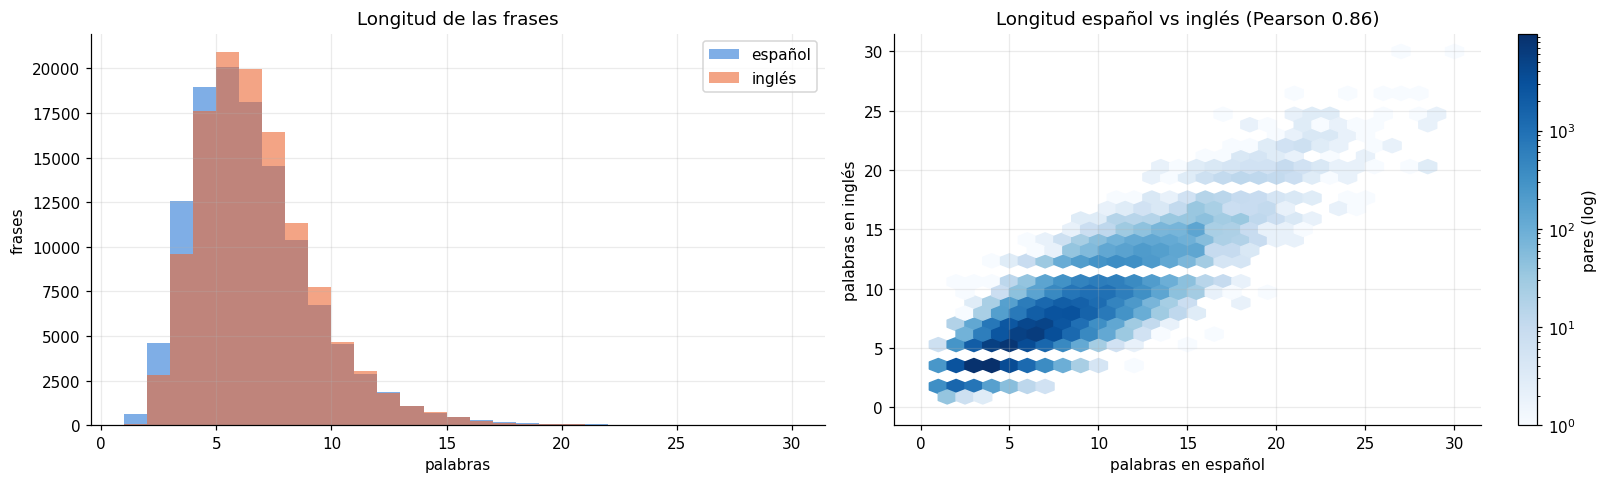

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

bins = np.arange(1, 31)
axes[0].hist(words["es"], bins=bins, alpha=0.6, color=PALETTE[0], label="español")
axes[0].hist(words["en"], bins=bins, alpha=0.6, color=PALETTE[1], label="inglés")
axes[0].set(title="Longitud de las frases", xlabel="palabras", ylabel="frases")
axes[0].legend()

hb = axes[1].hexbin(words["es"], words["en"], gridsize=30, extent=(0, 30, 0, 30), mincnt=1, bins="log", cmap="Blues")
axes[1].set(title=f"Longitud español vs inglés (Pearson {words['es'].corr(words['en']):.2f})", xlabel="palabras en español", ylabel="palabras en inglés")
fig.colorbar(hb, ax=axes[1], label="pares (log)")

fig.tight_layout()
plt.show()

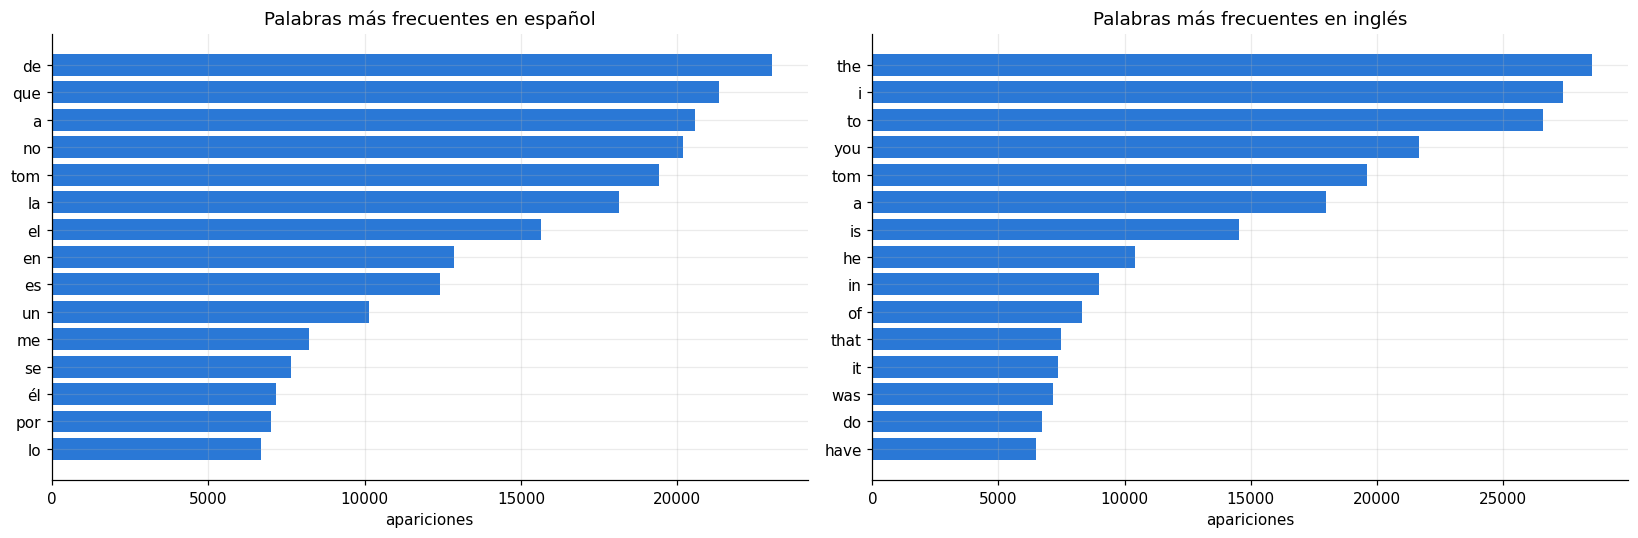

Frases en inglés que mencionan a Tom: 17.1%


In [50]:
def top_words(series, n=15):
    return series.str.lower().str.findall(r"[a-záéíóúüñ']+").explode().value_counts().head(n)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, lang, title in zip(axes, ["es", "en"], ["español", "inglés"]):
    top = top_words(raw[lang])
    ax.barh(top.index, top.values, color=PALETTE[0])
    ax.set(title=f"Palabras más frecuentes en {title}", xlabel="apariciones")
fig.tight_layout()
plt.show()

tom_share = raw["en"].str.contains(r"\bTom\b").mean()
print(f"Frases en inglés que mencionan a Tom: {tom_share:.1%}")

**Decisiones sobre spa-eng**
- No hay nulos ni pares duplicados, pero algunas frases en español tienen varias traducciones válidas. La división train/val/test se hace **por frase en español**, para que una misma frase nunca aparezca en dos particiones.
- Las frases son cortas y cotidianas, y el corpus tiene sesgos propios de Tatoeba (por ejemplo, muchas frases sobre "Tom"). OPUS-100 aporta la variedad que le falta.

### 2.2 OPUS-100 en-es

OPUS-100 trae 1.000.000 de pares de train y 2.000 de validación y de test. Mezcla subtítulos de películas, documentos de la ONU y la UE, prospectos de medicamentos y manuales de software. Al revisar una muestra aparecen problemas que hay que limpiar antes de usarlo: pares desalineados (*"Good night, ma'am."* → *"Esta tarde, hubo conciertos..."*), nombres sin traducir, URLs, códigos, marcas de software (`& kchart;`) y letras de canciones marcadas con ♪ o #.

In [51]:
opus = load_dataset("Helsinki-NLP/opus-100", "en-es")
opus_raw = {
    split: opus[split].flatten().to_pandas().rename(columns={"translation.en": "en", "translation.es": "es"})[["en", "es"]]
    for split in ("train", "validation", "test")
}
print(pd.Series({split: len(frame) for split, frame in opus_raw.items()}, name="pares").to_string())
opus_raw["train"].sample(10, random_state=SEED)

train         1000000
validation       2000
test             2000


,en,es
229916,Cell members come together and soak in the presence of God under the guidance of anointed worshi...,Y aquí es donde la adoración en el grupo más grande puede ser una experiencia transformadora don...
443987,One-day tour. We will start at Chequereq going towards Maras. Visit to the Moray archaeological ...,"Tour de un día, el cual iniciamos en Chequereq con dirección a Maras."
276251,She must have been dragged out from under the table.,Debe haber sido sacada a rastras de debajo de la mesa.
183701,What'll you do there?,¿Qué van a hacer allí?
749614,Is a metaphor.,Es una metáfora.
987038,So he lied.,Así que mintió.
265626,"In paragraph 4, the General Assembly calls on both sides to start the comprehensive and immediat...","En el párrafo 4, la Asamblea General exhorta a las dos partes a que comiencen a poner en práctic..."
771759,"It Weighs 50,000 KG and ranges over 8,000 meters",Su peso es de 50.000 kg y los rangos de más de 8.000 metros
571963,- Maybe even probation.,- Puede que en condicional.
881642,Dad and I love each other as always.,Papá y yo nos queremos lo mismo que siempre.


**Filtros de coherencia** (se aplican en este orden y cada par se descarta por el primero que falla):
1. **vacío**: algún lado queda vacío tras quitar el guion de diálogo inicial (`- Hola.` → `Hola.`).
2. **sin traducir**: el español y el inglés son idénticos (nombres, números, códigos).
3. **url o markup**: enlaces o entidades tipo `& kchart;`.
4. **letras de canciones**: líneas con ♪, ¶ o #.
5. **pocas letras**: menos de la mitad de los caracteres (sin contar espacios) son letras.
6. **demasiado larga**: más de 40 palabras en algún lado.
7. **longitud incoherente**: la proporción de caracteres español/inglés cae fuera de [0.5, 2.0]. El rango sale de spa-eng, donde el 98 % de los pares está entre 0.62 y 1.66.
8. **idioma cruzado**: el lado en español tiene más palabras típicas del inglés que del español, o al revés.

Al final se eliminan los pares duplicados.

In [52]:
class OpusCleaner:
    letters = r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]"
    markup = r"https?://|www\.|&\s*\w+;"
    es_words = {"el", "la", "los", "las", "que", "de", "del", "y", "en", "una", "por", "para", "con", "es", "se"}
    en_words = {"the", "and", "you", "is", "are", "this", "that", "with", "what", "of", "to", "it"}

    def __init__(self, min_ratio=0.5, max_ratio=2.0, max_words=40, min_letter_share=0.5):
        self.min_ratio = min_ratio
        self.max_ratio = max_ratio
        self.max_words = max_words
        self.min_letter_share = min_letter_share

    @staticmethod
    def normalize(series):
        return series.str.replace(r"^\s*-\s*", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

    def letter_share(self, series):
        return series.str.count(self.letters) / series.str.count(r"\S").clip(lower=1)

    @staticmethod
    def count_words(series, vocabulary):
        return series.str.findall(r"[a-záéíóúüñ']+").map(lambda words: sum(w in vocabulary for w in words))

    def audit(self, frame):
        es, en = self.normalize(frame["es"]), self.normalize(frame["en"])
        es_lower, en_lower = es.str.lower(), en.str.lower()
        ratio = es.str.len() / en.str.len().clip(lower=1)
        checks = {
            "vacío": (es == "") | (en == ""),
            "sin traducir": es_lower == en_lower,
            "url o markup": es.str.contains(self.markup) | en.str.contains(self.markup),
            "letras de canciones": es.str.contains("[♪¶#]") | en.str.contains("[♪¶#]"),
            "pocas letras": (self.letter_share(es) < self.min_letter_share) | (self.letter_share(en) < self.min_letter_share),
            "demasiado larga": (es.str.split().str.len() > self.max_words) | (en.str.split().str.len() > self.max_words),
            "longitud incoherente": ~ratio.between(self.min_ratio, self.max_ratio),
            "idioma cruzado": (self.count_words(es_lower, self.en_words) > self.count_words(es_lower, self.es_words))
                              | (self.count_words(en_lower, self.es_words) > self.count_words(en_lower, self.en_words)),
        }
        reason = pd.Series(np.nan, index=frame.index, dtype=object)
        for name, mask in reversed(list(checks.items())):
            reason[mask] = name
        return pd.DataFrame({"es": es, "en": en, "motivo": reason})

    def clean(self, frame):
        audited = self.audit(frame)
        valid = audited[audited["motivo"].isna()]
        clean = valid[["es", "en"]].drop_duplicates().reset_index(drop=True)
        summary = audited["motivo"].value_counts()
        summary["duplicado"] = len(valid) - len(clean)
        summary["conservado"] = len(clean)
        return clean, audited, summary

cleaner = OpusCleaner()
opus_clean, opus_audit, opus_summary = {}, {}, {}
for split, frame in opus_raw.items():
    opus_clean[split], opus_audit[split], opus_summary[split] = cleaner.clean(frame)

summary = pd.DataFrame(opus_summary).fillna(0).astype(int)
summary["% train"] = (100 * summary["train"] / len(opus_raw["train"])).round(2)
summary

,train,validation,test,% train
motivo,,,,
conservado,811655,1758,1745,81.17
demasiado larga,47918,124,137,4.79
duplicado,70018,2,1,7.00
idioma cruzado,1938,3,2,0.19
letras de canciones,3900,7,7,0.39
longitud incoherente,34268,58,70,3.43
pocas letras,8124,10,13,0.81
sin traducir,20289,30,22,2.03
url o markup,1862,8,3,0.19


Ejemplos de lo que descarta cada filtro, para comprobar que el filtro tiene sentido:

In [53]:
discarded = opus_audit["train"].dropna(subset=["motivo"])
discarded.sample(frac=1, random_state=SEED).groupby("motivo").head(3).sort_values("motivo")[["motivo", "es", "en"]]

,motivo,es,en
896977,demasiado larga,"Si el nivel de barrera de cruce no es visible desde el punto en el que se rige a distancia, debe...",If the barrier level crossing is not visible from the point at which it is governed at a distanc...
74197,demasiado larga,"Sr. D'Alotto (Argentina): En su reciente intervención ante este foro, el Presidente de la Repúbl...","Mr. D'Alotto (Argentina) (spoke in Spanish): In his recent statement in the Assembly, the Presid..."
297502,demasiado larga,La absorción es pobre debido a la rápida conversión de yodo a yoduro[ii]y esto podría explicar p...,Absorption is poor due to rapid conversion of iodine to iodide [ii] and this might explain why o...
862923,idioma cruzado,== Record low temperatures ===== Suecia ===Many cities in Suecia had their coldest December sinc...,== Record low temperatures ===== Sweden ===Many cities in Sweden had their coldest December sinc...
602618,idioma cruzado,"Sí, eso is.","Yes, it is."
16201,idioma cruzado,"también las intervenciones de Francia (Actas resumidas (A/CONF.39/11) (nota 567, supra), 22ª ses...","See also interventions by France (Summary Records (A/CONF.39/11) (footnote 567 above), 22nd meet..."
523413,letras de canciones,# en la cuna de los amorosos brazos del Señor # # detrás de la noche # # oye a los ángeles dormi...,♪ in the cradle of the Lord's loving arms ♪ ♪ behind the night ♪ ♪ hear the angels fall asleep s...
506688,letras de canciones,# Y a través de la música,♪ And through music
69329,letras de canciones,@ImadMesdoua: #Romney conoce bien el MENA .,@ImadMesdoua: #Romney knows MENA well.
126353,longitud incoherente,No pares. - Chicos... chicos.,"Guys, guys."


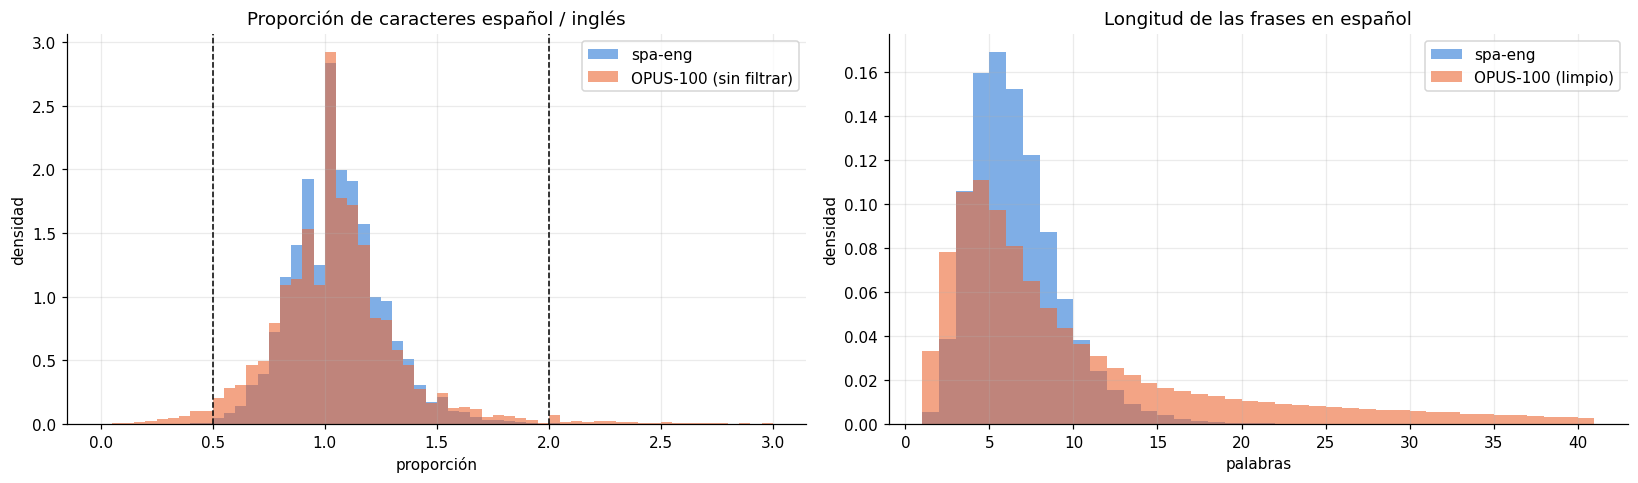

In [54]:
tatoeba_ratio = raw["es"].str.len() / raw["en"].str.len()
opus_ratio = opus_audit["train"]["es"].str.len() / opus_audit["train"]["en"].str.len().clip(lower=1)
opus_words = opus_clean["train"]["es"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.linspace(0, 3, 61)
axes[0].hist(tatoeba_ratio, bins=bins, density=True, alpha=0.6, color=PALETTE[0], label="spa-eng")
axes[0].hist(opus_ratio, bins=bins, density=True, alpha=0.6, color=PALETTE[1], label="OPUS-100 (sin filtrar)")
for bound in (cleaner.min_ratio, cleaner.max_ratio):
    axes[0].axvline(bound, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Proporción de caracteres español / inglés", xlabel="proporción", ylabel="densidad")
axes[0].legend()

bins = np.arange(1, 42)
axes[1].hist(words["es"], bins=bins, density=True, alpha=0.6, color=PALETTE[0], label="spa-eng")
axes[1].hist(opus_words, bins=bins, density=True, alpha=0.6, color=PALETTE[1], label="OPUS-100 (limpio)")
axes[1].set(title="Longitud de las frases en español", xlabel="palabras", ylabel="densidad")
axes[1].legend()

fig.tight_layout()
plt.show()

Lectura manual de una muestra de pares que pasaron los filtros:

In [55]:
opus_clean["train"].sample(15, random_state=SEED)

,es,en
10399,Te han oído...,You were heard.
207571,Voy a viajar.,I'm going to travel.
173399,Herr Zweig era un miembro prominente de Ia comunidad judaica.,Herr Zweig was a prominent member of the Jewish community.
719258,"No, me refiero a... ¿una botella de agua?","No, I meant... bottled water?"
752282,Trevor y Scott estuvieron en su granja y vieron las deplorables condiciones.,Trevor and Scott were both at his farm and said the conditions were deplorable.
578845,El hombre en sociedad debe tomar algunas decisiones acerca de los aciertos o equívocos de cierto...,INTERVIEWER 3: Yet man in society must make some decisions about the rights and wrongs of certai...
350606,"Ahora que no hay bebé, el divorcio será más sencillo.","Now that there's no baby, it'll make the divorce a lot simpler."
794911,"Te extrañé, Eun Young.","I missed you, Eun Young."
770442,"Costa Rica adoptó, a través de la Ley Nº 5980, la Convención para la Protección del Patrimonio M...","By Law No. 980, Costa Rica adopted the Convention Concerning the Protection of the World Cultura..."
787860,"Nuestro carro era marrón, este carro es marrón.","Our buggy was tan, this buggy is tan."


### 2.3 Mezcla final

Se combinan spa-eng completo y **400.000 pares** de OPUS-100 limpio para train. Validación y test juntan la partición correspondiente de spa-eng con la validación y el test oficiales de OPUS-100 (también limpios). Por último, se quitan de train los pares repetidos y cualquier frase en español que aparezca en validación o test.

## 3. Tokenizador y dataset

In [56]:
def split_by_source(frame, val_frac, test_frac, seed):
    sources = frame["es"].drop_duplicates().sample(frac=1, random_state=seed).to_numpy()
    n_val, n_test = int(len(sources) * val_frac), int(len(sources) * test_frac)
    groups = {"test": sources[:n_test], "val": sources[n_test:n_test + n_val], "train": sources[n_test + n_val:]}
    return {name: frame[frame["es"].isin(set(group))].reset_index(drop=True) for name, group in groups.items()}


OPUS_TRAIN_PAIRS = 400_000

tatoeba = split_by_source(raw, val_frac=0.05, test_frac=0.05, seed=SEED)
opus_parts = {
    "train": opus_clean["train"].sample(min(OPUS_TRAIN_PAIRS, len(opus_clean["train"])), random_state=SEED),
    "val": opus_clean["validation"],
    "test": opus_clean["test"],
}
splits = {
    name: pd.concat([tatoeba[name].assign(source="spa-eng"), opus_parts[name].assign(source="opus")], ignore_index=True)
    for name in ("train", "val", "test")
}
held_out = set(splits["val"]["es"]) | set(splits["test"]["es"])
splits["train"] = splits["train"][~splits["train"]["es"].isin(held_out)].drop_duplicates(["es", "en"]).reset_index(drop=True)

pd.DataFrame({name: frame["source"].value_counts() for name, frame in splits.items()}).T.assign(total=lambda d: d.sum(axis=1))

source,opus,spa-eng,total
train,397544,107062,504606
val,1758,5926,7684
test,1745,5930,7675


El tokenizador es un **BPE a nivel de byte** (el mismo tipo que usa GPT-2), pero entrenado desde cero con las frases de train en ambos idiomas. Así el vocabulario se ajusta al español y al inglés de la mezcla. Con OPUS el vocabulario es mucho más variado, por eso se usan 16.000 tokens. Se añaden cuatro tokens especiales: `<pad>`, `<es>`, `<en>` y `<eos>`.

In [57]:
class BilingualTokenizer:
    specials = ["<pad>", "<es>", "<en>", "<eos>"]

    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
        self.pad_id, self.es_id, self.en_id, self.eos_id = (tokenizer.token_to_id(t) for t in self.specials)

    @classmethod
    def train(cls, texts, vocab_size):
        tokenizer = Tokenizer(models.BPE())
        tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tokenizer.decoder = decoders.ByteLevel()
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=cls.specials, show_progress=False,
                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
        tokenizer.train_from_iterator(texts, trainer)
        return cls(tokenizer)

    @property
    def vocab_size(self):
        return self.tokenizer.get_vocab_size()

    def encode(self, texts):
        return [e.ids for e in self.tokenizer.encode_batch(list(texts))]

    def decode(self, ids):
        return self.tokenizer.decode(ids)

    def pieces(self, ids):
        return [self.tokenizer.decode([i], skip_special_tokens=False) for i in ids]

    def prompt(self, source_ids):
        return [self.es_id, *source_ids, self.en_id]


tokenizer = BilingualTokenizer.train(pd.concat([splits["train"]["es"], splits["train"]["en"]]), vocab_size=16000)
tokenizer.tokenizer.save(str(WORK_DIR / "tokenizer.json"))
print("vocabulario:", tokenizer.vocab_size)

for sentence in ["¿Dónde está la estación de tren?", "Where is the train station?"]:
    print(" | ".join(tokenizer.pieces(tokenizer.encode([sentence])[0])))

vocabulario: 16000
¿ | Dónde |  está |  la |  estación |  de |  tren | ?
Where |  is |  the |  train |  station | ?


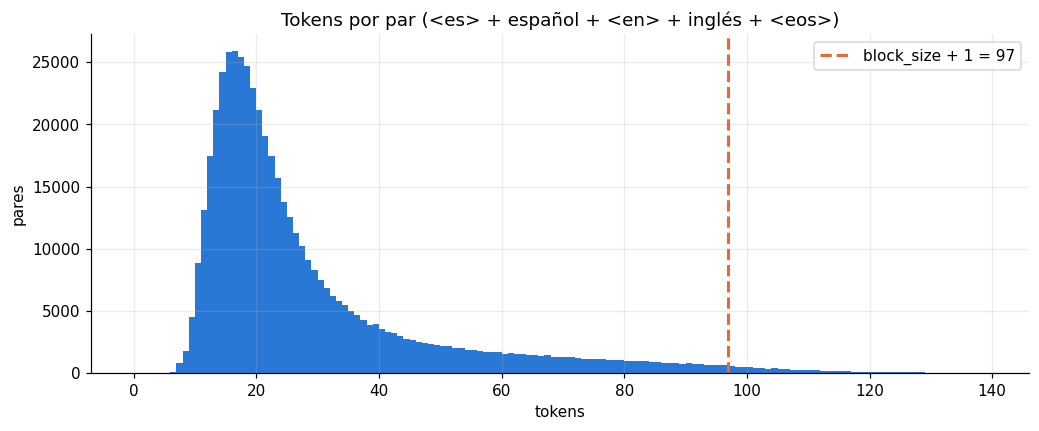

train: se conservan 98.50% de los pares | opus 98.10% | spa-eng 100.00%
val  : se conservan 99.32% de los pares | opus 97.10% | spa-eng 99.98%
test : se conservan 99.57% de los pares | opus 98.11% | spa-eng 100.00%


In [58]:
BLOCK_SIZE = 96

pair_tokens = {
    name: np.array([len(s) + len(t) + 3 for s, t in zip(tokenizer.encode(frame["es"]), tokenizer.encode(frame["en"]))])
    for name, frame in splits.items()
}

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(pair_tokens["train"], bins=np.arange(0, 140), color=PALETTE[0])
ax.axvline(BLOCK_SIZE + 1, color=PALETTE[1], linestyle="--", label=f"block_size + 1 = {BLOCK_SIZE + 1}")
ax.set(title="Tokens por par (<es> + español + <en> + inglés + <eos>)", xlabel="tokens", ylabel="pares")
ax.legend()
plt.show()

for name in splits:
    keep = pair_tokens[name] <= BLOCK_SIZE + 1
    by_source = splits[name].assign(keep=keep).groupby("source")["keep"].mean()
    print(f"{name:5s}: se conservan {keep.mean():.2%} de los pares | " + " | ".join(f"{k} {v:.2%}" for k, v in by_source.items()))
    splits[name] = splits[name][keep].reset_index(drop=True)

Cada par se convierte en `x` (entrada) e `y` (objetivo desplazado una posición). Las posiciones del prompt en español se marcan con `-1` en `y`, así que la loss se calcula **solo sobre la traducción al inglés y el `<eos>`**. Los batches se rellenan con `<pad>` hasta la frase más larga del batch.

In [59]:
class TranslationDataset(Dataset):
    def __init__(self, frame, tokenizer):
        self.tokenizer = tokenizer
        self.sources = tokenizer.encode(frame["es"])
        self.targets = tokenizer.encode(frame["en"])

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, i):
        prompt = self.tokenizer.prompt(self.sources[i])
        sequence = torch.tensor(prompt + self.targets[i] + [self.tokenizer.eos_id])
        x, y = sequence[:-1], sequence[1:].clone()
        y[:len(prompt) - 1] = -1
        return x, y

    def collate(self, batch):
        xs, ys = zip(*batch)
        x = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=self.tokenizer.pad_id)
        y = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=-1)
        return x, y


datasets = {name: TranslationDataset(frame, tokenizer) for name, frame in splits.items()}

x, y = datasets["train"][0]
print("x:", " | ".join(tokenizer.pieces(x.tolist())))
print("y:", " | ".join("·" if t == -1 else tokenizer.pieces([t])[0] for t in y.tolist()))

x: <es> | Ve | . | <en> | Go | .
y: · | · | · | Go | . | <eos>


## 4. Modelo

Arquitectura de minGPT: embeddings de token y posición, bloques `LayerNorm → atención causal → LayerNorm → MLP` con conexiones residuales, y una capa final `lm_head`. La atención usa `scaled_dot_product_attention` para entrenar más rápido, y la versión explícita de minGPT solo cuando se quieren guardar los mapas de atención para visualizarlos.

In [60]:
@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int
    n_layer: int = 6
    n_head: int = 8
    n_embd: int = 512
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head
        self.store_attention = False
        self.attention = None

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(C, dim=2)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        if self.store_attention:
            att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
            att = att.masked_fill(~torch.ones(T, T, dtype=torch.bool, device=x.device).tril(), float("-inf")).softmax(dim=-1)
            self.attention = att.detach()
            y = self.attn_dropout(att) @ v
        else:
            y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_dropout.p if self.training else 0.0, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.c_proj(y))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(config.n_embd, 4 * config.n_embd),
            nn.GELU(approximate="tanh"),
            nn.Linear(4 * config.n_embd, config.n_embd),
            nn.Dropout(config.dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        return x + self.mlp(self.ln_2(x))


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            drop=nn.Dropout(config.dropout),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight") or name.endswith("mlp.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def forward(self, idx, targets=None):
        pos = torch.arange(idx.size(1), device=idx.device)
        x = self.transformer.drop(self.transformer.wte(idx) + self.transformer.wpe(pos))
        for block in self.transformer.h:
            x = block(x)
        logits = self.lm_head(self.transformer.ln_f(x))
        if targets is None:
            return logits
        return F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1).unsqueeze(0)

    def configure_optimizers(self, config):
        decay = [p for n, p in self.named_parameters() if p.dim() >= 2 and "wte" not in n and "wpe" not in n]
        no_decay = [p for n, p in self.named_parameters() if p.dim() < 2 or "wte" in n or "wpe" in n]
        groups = [{"params": decay, "weight_decay": config.weight_decay}, {"params": no_decay, "weight_decay": 0.0}]
        return torch.optim.AdamW(groups, lr=config.learning_rate, betas=config.betas)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, eos_id):
        finished = torch.zeros(idx.size(0), dtype=torch.bool, device=idx.device)
        for _ in range(max_new_tokens):
            logits = self(idx[:, -self.config.block_size:])
            next_id = logits[:, -1, :].argmax(dim=-1, keepdim=True)
            next_id = next_id.masked_fill(finished[:, None], eos_id)
            finished |= next_id.squeeze(1) == eos_id
            idx = torch.cat((idx, next_id), dim=1)
            if finished.all():
                break
        return idx

    def parameter_table(self):
        rows = []
        for name, p in self.named_parameters():
            parts = name.split(".")
            if parts[0] == "lm_head":
                layer, group = "lm_head", "lm_head"
            elif parts[1] != "h":
                layer, group = parts[1], {"wte": "token_embedding", "wpe": "position_embedding", "ln_f": "layernorm"}[parts[1]]
            else:
                layer, group = f"block_{parts[2]}", {"attn": "attention", "mlp": "mlp"}.get(parts[3], "layernorm")
            rows.append(dict(name=name, layer=layer, group=group, shape=tuple(p.shape), params=p.numel()))
        return pd.DataFrame(rows)

In [61]:
model_config = GPTConfig(vocab_size=tokenizer.vocab_size, block_size=BLOCK_SIZE)
model = GPT(model_config)
print(model)
pd.Series(asdict(model_config), name="valor", dtype=object).to_frame()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(16000, 512)
    (wpe): Embedding(96, 512)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=512, out_features=1536, bias=True)
          (c_proj): Linear(in_features=512, out_features=512, bias=True)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (mlp): Sequential(
          (0): Linear(in_features=512, out_features=2048, bias=True)
          (1): GELU(approximate='tanh')
          (2): Linear(in_features=2048, out_features=512, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_fe

,valor
vocab_size,16000
block_size,96
n_layer,6
n_head,8
n_embd,512
dropout,0.1


Parámetros totales:                35.35M
Tokens objetivo en train:          6.55M
Tokens objetivo por parámetro:     0.19


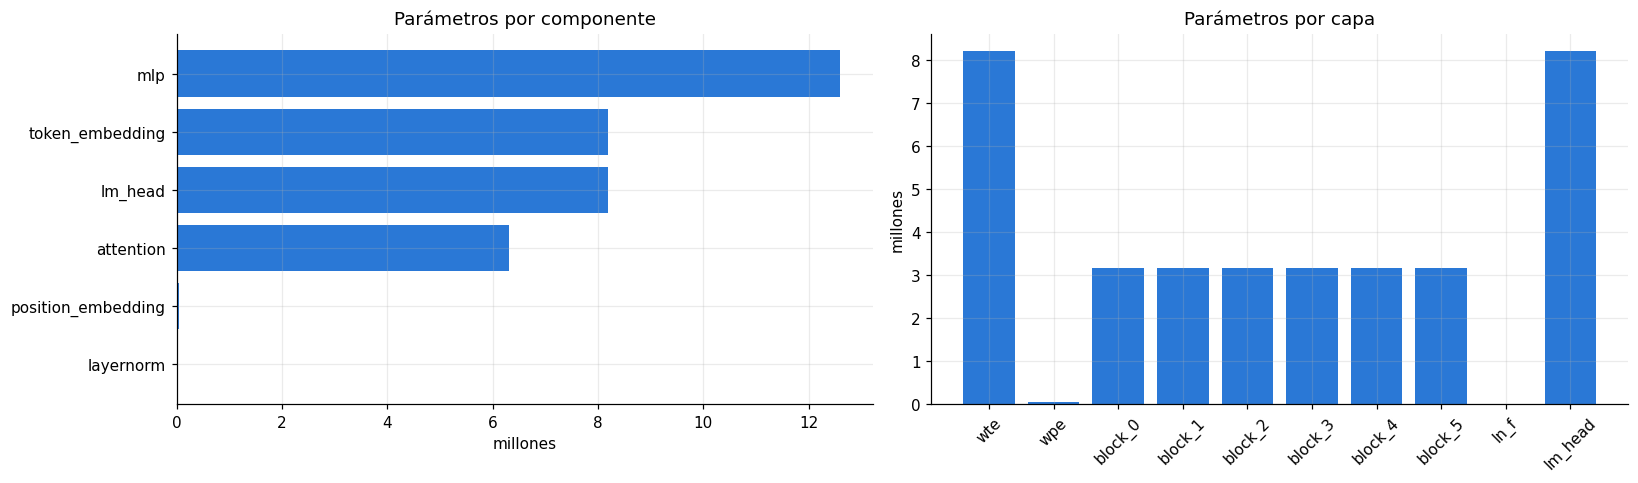

,parámetros,%
group,,
mlp,12598272,35.64
token_embedding,8192000,23.17
lm_head,8192000,23.17
attention,6303744,17.83
position_embedding,49152,0.14
layernorm,13312,0.04


In [62]:
params = model.parameter_table()
n_params = params["params"].sum()
train_targets = sum(int((y != -1).sum()) for _, y in datasets["train"])

print(f"Parámetros totales:                {n_params / 1e6:.2f}M")
print(f"Tokens objetivo en train:          {train_targets / 1e6:.2f}M")
print(f"Tokens objetivo por parámetro:     {train_targets / n_params:.2f}")

by_group = params.groupby("group")["params"].sum().sort_values()
by_layer = params.groupby("layer", sort=False)["params"].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh(by_group.index, by_group.values / 1e6, color=PALETTE[0])
axes[0].set(title="Parámetros por componente", xlabel="millones")
axes[1].bar(by_layer.index, by_layer.values / 1e6, color=PALETTE[0])
axes[1].set(title="Parámetros por capa", ylabel="millones")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

by_group.to_frame("parámetros").assign(**{"%": lambda d: (100 * d["parámetros"] / n_params).round(2)})[::-1]

## 5. Trainer

El `Trainer` sigue la idea del de minGPT (AdamW con *weight decay* solo en matrices y *gradient clipping*), y añade:
- mixed precision fp16 con `torch.amp.autocast("cuda")` y `torch.amp.GradScaler("cuda")` (las T4 no soportan bf16),
- learning rate con warmup lineal y decaimiento coseno,
- early stopping sobre la loss de validación, guardando el mejor checkpoint,
- `nn.DataParallel` cuando se usan las 2 GPUs.

In [63]:
@dataclass
class TrainConfig:
    batch_size: int = 256
    learning_rate: float = 6e-4
    min_lr_ratio: float = 0.1
    warmup_steps: int = 300
    max_epochs: int = 20
    weight_decay: float = 0.1
    betas: tuple = (0.9, 0.95)
    grad_norm_clip: float = 1.0
    patience: int = 5
    log_interval: int = 20


class Trainer:
    def __init__(self, model, config, train_ds, val_ds, n_gpus):
        self.model = model.to(DEVICE)
        self.net = nn.DataParallel(model) if n_gpus > 1 else model
        self.config = config
        self.optimizer = model.configure_optimizers(config)
        self.use_amp = DEVICE.type == "cuda"
        self.scaler = torch.amp.GradScaler("cuda", enabled=self.use_amp)
        loader_args = dict(batch_size=config.batch_size, num_workers=2, pin_memory=self.use_amp)
        self.train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, collate_fn=train_ds.collate, **loader_args)
        self.val_loader = DataLoader(val_ds, collate_fn=val_ds.collate, **loader_args)
        self.total_steps = len(self.train_loader) * config.max_epochs
        self.step = 0
        self.history = {"steps": [], "epochs": []}

    def lr_at(self, step):
        c = self.config
        if step < c.warmup_steps:
            return c.learning_rate * (step + 1) / c.warmup_steps
        progress = min(1.0, (step - c.warmup_steps) / (self.total_steps - c.warmup_steps))
        return c.learning_rate * (c.min_lr_ratio + (1 - c.min_lr_ratio) * 0.5 * (1 + math.cos(math.pi * progress)))

    def train_step(self, x, y):
        lr = self.lr_at(self.step)
        for group in self.optimizer.param_groups:
            group["lr"] = lr
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=self.use_amp):
            loss = self.net(x, y).mean()
        self.optimizer.zero_grad(set_to_none=True)
        self.scaler.scale(loss).backward()
        self.scaler.unscale_(self.optimizer)
        grad_norm = nn.utils.clip_grad_norm_(self.model.parameters(), self.config.grad_norm_clip)
        self.scaler.step(self.optimizer)
        self.scaler.update()
        self.step += 1
        return loss.item(), grad_norm.item(), lr

    @torch.no_grad()
    def evaluate(self):
        self.net.eval()
        total, count = 0.0, 0
        for x, y in self.val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=self.use_amp):
                loss = self.net(x, y).mean()
            n = int((y != -1).sum())
            total, count = total + loss.item() * n, count + n
        self.net.train()
        return total / count

    def benchmark(self, steps, warmup=10):
        self.net.train()
        batches = iter(self.train_loader)
        tokens = 0
        for i in range(warmup + steps):
            if i == warmup:
                torch.cuda.synchronize()
                start, tokens = time.time(), 0
            x, y = next(batches)
            self.train_step(x, y)
            tokens += x.numel()
        torch.cuda.synchronize()
        return tokens / (time.time() - start)

    def fit(self, on_epoch_end=None):
        best_loss, best_state, bad_epochs = float("inf"), None, 0
        for epoch in range(1, self.config.max_epochs + 1):
            self.net.train()
            start, epoch_losses = time.time(), []
            for x, y in self.train_loader:
                loss, grad_norm, lr = self.train_step(x, y)
                epoch_losses.append(loss)
                if self.step % self.config.log_interval == 0:
                    self.history["steps"].append(dict(step=self.step, loss=loss, grad_norm=grad_norm, lr=lr))
            record = dict(epoch=epoch, step=self.step, train_loss=float(np.mean(epoch_losses)), val_loss=self.evaluate(),
                          time_sec=time.time() - start)
            record.update(on_epoch_end(self) if on_epoch_end else {})
            improved = record["val_loss"] < best_loss
            if improved:
                best_loss, bad_epochs = record["val_loss"], 0
                best_state = copy.deepcopy(self.model.state_dict())
                torch.save(best_state, WORK_DIR / "best_model.pt")
            else:
                bad_epochs += 1
            self.history["epochs"].append(record)
            extra = " | ".join(f"{k} {v:.2f}" for k, v in record.items() if k not in ("epoch", "step", "train_loss", "val_loss", "time_sec"))
            print(f"epoch {epoch:2d} | train {record['train_loss']:.4f} | val {record['val_loss']:.4f} | {extra} | "
                  f"{record['time_sec']:.0f}s{' | best' if improved else ''}")
            if bad_epochs >= self.config.patience:
                print(f"early stopping: {self.config.patience} épocas sin mejorar la val loss")
                break
        self.model.load_state_dict(best_state)
        return self.history


train_config = TrainConfig()
pd.Series(asdict(train_config), name="valor", dtype=object).to_frame()

,valor
batch_size,256
learning_rate,0.0006
min_lr_ratio,0.1
warmup_steps,300
max_epochs,20
weight_decay,0.1
betas,"(0.9, 0.95)"
grad_norm_clip,1.0
patience,5
log_interval,20


## 6. ¿Conviene usar las 2 GPUs?

Dentro de un notebook la forma directa de usar dos GPUs es `nn.DataParallel`: en cada paso divide el batch entre las dos tarjetas, copia el modelo a la segunda y junta los resultados en la primera. Con modelos pequeños y frases cortas ese costo extra puede comerse toda la ganancia, así que se mide el throughput con el **mismo batch global** en ambos casos y solo se usan 2 GPUs si el speedup es de al menos **1.2x**.

speedup 2 vs 1 GPU: 1.84x -> se entrena con 2 GPU(s)


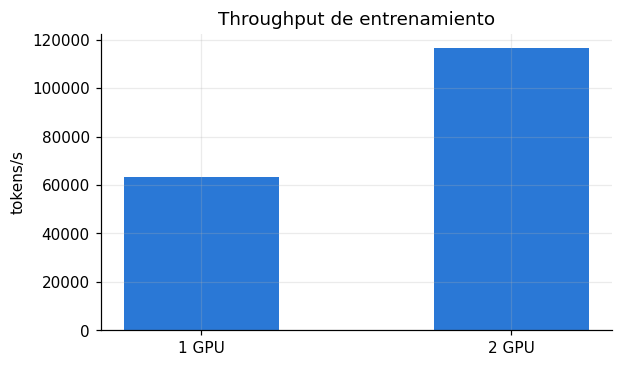

In [64]:
MIN_SPEEDUP = 1.2

def measure(n_gpus, steps=60):
    torch.manual_seed(SEED)
    trainer = Trainer(GPT(model_config), train_config, datasets["train"], datasets["val"], n_gpus)
    tokens_per_sec = trainer.benchmark(steps)
    del trainer
    torch.cuda.empty_cache()
    return tokens_per_sec


if N_GPUS >= 2:
    bench = pd.Series({f"{n} GPU": measure(n) for n in (1, 2)}, name="tokens/s")
    speedup = bench["2 GPU"] / bench["1 GPU"]
    USE_GPUS = 2 if speedup >= MIN_SPEEDUP else 1
    print(f"speedup 2 vs 1 GPU: {speedup:.2f}x -> se entrena con {USE_GPUS} GPU(s)")

    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(bench.index, bench.values, color=PALETTE[0], width=0.5)
    ax.set(title="Throughput de entrenamiento", ylabel="tokens/s")
    plt.show()
else:
    USE_GPUS = 1
    print("solo hay una GPU disponible -> se entrena con 1")

## 7. Entrenamiento

Además de la loss, al final de cada época se traduce una muestra fija de 1.000 frases de validación y se calcula su **BLEU** para ver la calidad de la traducción mientras entrena.

In [65]:
class Translator:
    def __init__(self, model, tokenizer, batch_size=512):
        self.model = model
        self.tokenizer = tokenizer
        self.batch_size = batch_size

    @torch.no_grad()
    def translate(self, sentences, max_new_tokens=BLOCK_SIZE):
        self.model.eval()
        prompts = [self.tokenizer.prompt(ids) for ids in self.tokenizer.encode(sentences)]
        outputs = [None] * len(prompts)
        by_length = pd.Series(range(len(prompts))).groupby([len(p) for p in prompts])
        for length, rows in by_length:
            rows = rows.tolist()
            for start in range(0, len(rows), self.batch_size):
                chunk = rows[start:start + self.batch_size]
                idx = torch.tensor([prompts[i] for i in chunk], device=DEVICE)
                with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                    generated = self.model.generate(idx, max_new_tokens, self.tokenizer.eos_id)[:, length:].tolist()
                for i, ids in zip(chunk, generated):
                    outputs[i] = self.tokenizer.decode(ids[:ids.index(self.tokenizer.eos_id)] if self.tokenizer.eos_id in ids else ids)
        return outputs

    def score(self, frame):
        predictions = self.translate(frame["es"])
        return {"bleu": sacrebleu.corpus_bleu(predictions, [frame["en"].tolist()]).score,
                "chrf": sacrebleu.corpus_chrf(predictions, [frame["en"].tolist()]).score}


val_sample = splits["val"].sample(1000, random_state=SEED)

In [66]:
torch.manual_seed(SEED)
model = GPT(model_config)
trainer = Trainer(model, train_config, datasets["train"], datasets["val"], USE_GPUS)
translator = Translator(model, tokenizer)

print(f"GPUs: {USE_GPUS} | steps por época: {len(trainer.train_loader)} | batch: {train_config.batch_size}")
start = time.time()
history = trainer.fit(on_epoch_end=lambda t: {"val_bleu": translator.score(val_sample)["bleu"]})
print(f"tiempo total: {(time.time() - start) / 60:.1f} min")

GPUs: 2 | steps por época: 1941 | batch: 256
epoch  1 | train 3.8864 | val 1.9447 | val_bleu 30.40 | 394s | best
epoch  2 | train 2.5407 | val 1.5623 | val_bleu 37.81 | 394s | best
epoch  3 | train 2.1938 | val 1.4079 | val_bleu 40.56 | 395s | best
epoch  4 | train 2.0106 | val 1.3212 | val_bleu 42.15 | 395s | best
epoch  5 | train 1.8851 | val 1.2665 | val_bleu 44.51 | 395s | best
epoch  6 | train 1.7883 | val 1.2274 | val_bleu 44.78 | 395s | best
epoch  7 | train 1.7045 | val 1.1922 | val_bleu 45.81 | 395s | best
epoch  8 | train 1.6293 | val 1.1688 | val_bleu 46.85 | 395s | best
epoch  9 | train 1.5584 | val 1.1490 | val_bleu 46.62 | 395s | best
epoch 10 | train 1.4906 | val 1.1275 | val_bleu 47.95 | 395s | best
epoch 11 | train 1.4241 | val 1.1136 | val_bleu 48.17 | 394s | best
epoch 12 | train 1.3586 | val 1.1066 | val_bleu 48.64 | 395s | best
epoch 13 | train 1.2941 | val 1.0984 | val_bleu 49.58 | 395s | best
epoch 14 | train 1.2326 | val 1.0894 | val_bleu 50.40 | 395s | best
epo

## 8. Métricas de entrenamiento

In [67]:
steps = pd.DataFrame(history["steps"])
epochs = pd.DataFrame(history["epochs"]).assign(train_ppl=lambda d: np.exp(d["train_loss"]), val_ppl=lambda d: np.exp(d["val_loss"]))
epochs.round(4)

,epoch,step,train_loss,val_loss,time_sec,val_bleu,train_ppl,val_ppl
0,1,1941,3.8864,1.9447,393.5197,30.4042,48.7330,6.9914
1,2,3882,2.5407,1.5623,394.2717,37.8099,12.6885,4.7696
2,3,5823,2.1938,1.4079,394.6247,40.5562,8.9696,4.0875
3,4,7764,2.0106,1.3212,394.7528,42.1540,7.4675,3.7480
4,5,9705,1.8851,1.2665,394.5136,44.5126,6.5867,3.5483
5,6,11646,1.7883,1.2274,394.8487,44.7847,5.9791,3.4123
6,7,13587,1.7045,1.1922,394.5986,45.8069,5.4985,3.2944
7,8,15528,1.6293,1.1688,394.7789,46.8547,5.1001,3.2182
8,9,17469,1.5584,1.1490,394.6925,46.6165,4.7514,3.1551
9,10,19410,1.4906,1.1275,394.7186,47.9535,4.4400,3.0879


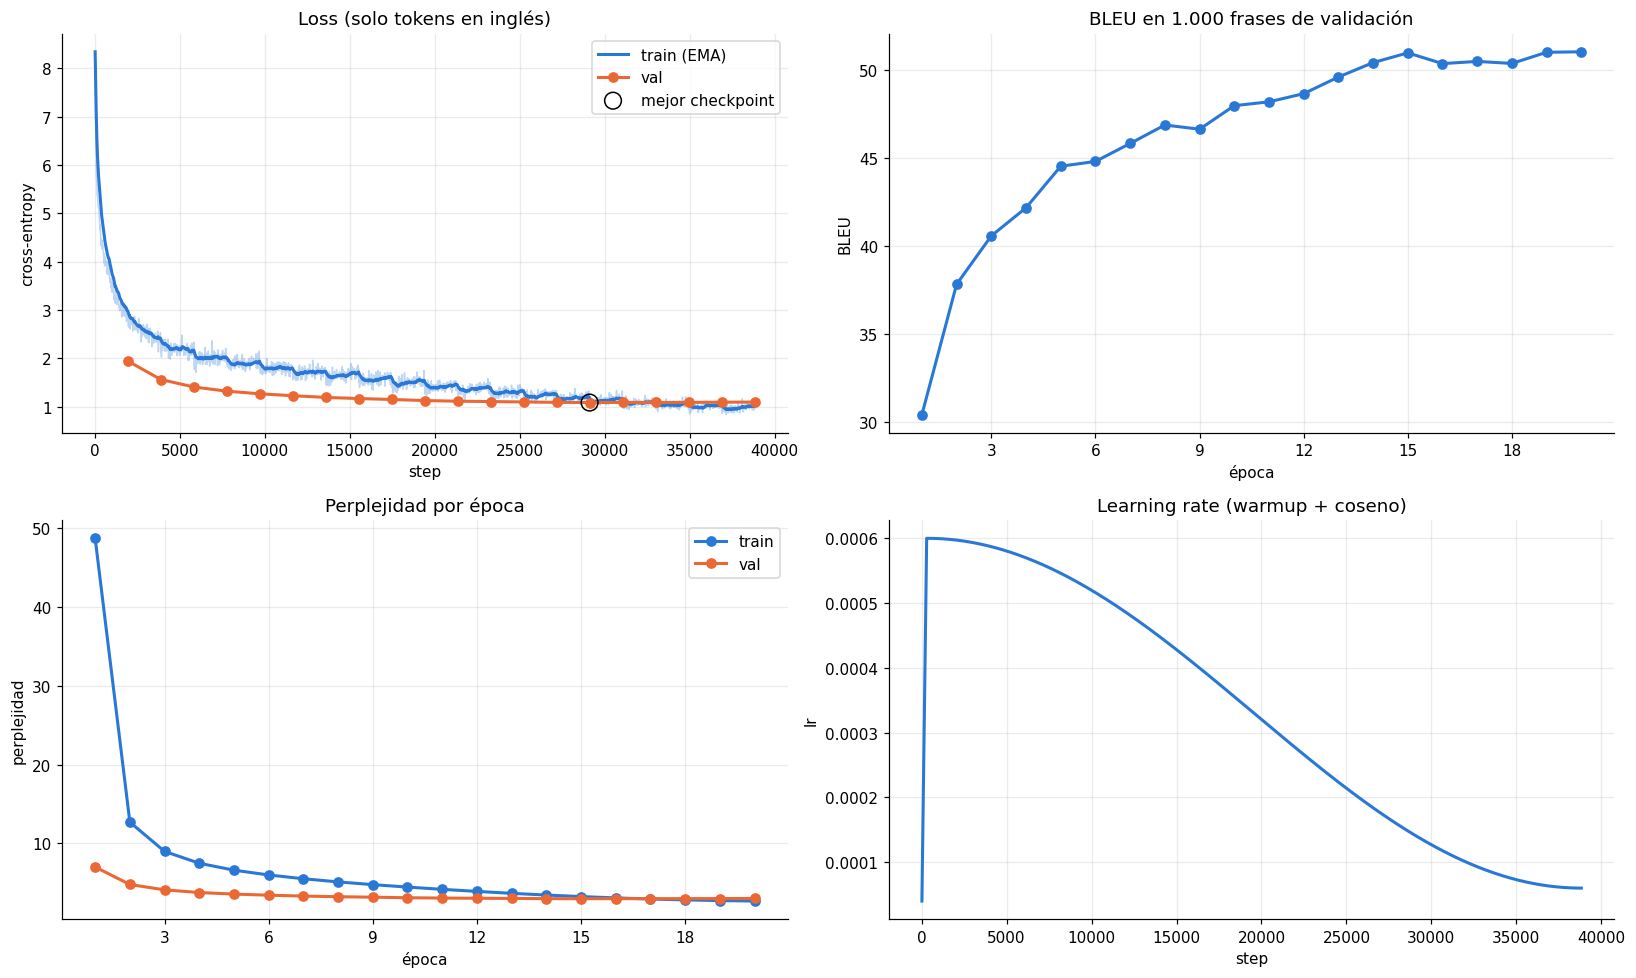

mejor época: 15 | val loss 1.0857 | val BLEU 50.95


In [68]:
best = epochs.loc[epochs["val_loss"].idxmin()]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

ax = axes[0, 0]
ax.plot(steps["step"], steps["loss"], color=PALETTE[0], alpha=0.3, linewidth=1)
ax.plot(steps["step"], steps["loss"].ewm(span=20).mean(), color=PALETTE[0], label="train (EMA)")
ax.plot(epochs["step"], epochs["val_loss"], color=PALETTE[1], marker="o", label="val")
ax.scatter([best["step"]], [best["val_loss"]], s=120, facecolors="none", edgecolors="black", zorder=3, label="mejor checkpoint")
ax.set(title="Loss (solo tokens en inglés)", xlabel="step", ylabel="cross-entropy")
ax.legend()

ax = axes[0, 1]
ax.plot(epochs["epoch"], epochs["val_bleu"], color=PALETTE[0], marker="o")
ax.set(title="BLEU en 1.000 frases de validación", xlabel="época", ylabel="BLEU")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax = axes[1, 0]
ax.plot(epochs["epoch"], epochs["train_ppl"], color=PALETTE[0], marker="o", label="train")
ax.plot(epochs["epoch"], epochs["val_ppl"], color=PALETTE[1], marker="o", label="val")
ax.set(title="Perplejidad por época", xlabel="época", ylabel="perplejidad")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend()

ax = axes[1, 1]
ax.plot(steps["step"], steps["lr"], color=PALETTE[0])
ax.set(title="Learning rate (warmup + coseno)", xlabel="step", ylabel="lr")

fig.tight_layout()
plt.show()

print(f"mejor época: {int(best['epoch'])} | val loss {best['val_loss']:.4f} | val BLEU {best['val_bleu']:.2f}")

La loss de train se mide con dropout activo y la de validación sin él, por eso al principio la de validación puede quedar por debajo. Si la de validación sube mientras la de train sigue bajando, el modelo está memorizando, y el early stopping se queda con la mejor época.

## 9. Testing

In [69]:
results = pd.DataFrame({name: translator.score(splits[name]) for name in ("val", "test")}).T
results.round(2)

,bleu,chrf
val,50.22,65.94
test,50.82,66.57


### 9.1 Ejemplos del conjunto de test

In [70]:
examples = splits["test"].sample(12, random_state=SEED).reset_index(drop=True)
examples["modelo"] = translator.translate(examples["es"])
examples.rename(columns={"es": "español", "en": "referencia"})[["español", "referencia", "modelo"]]

,español,referencia,modelo
0,Él se agarró un resfriado cuando salió a la lluvia.,He caught a chill because he went out in the rain.,He caught a cold when he went to the rain.
1,"Permiso, ¿puedo pasar?","Excuse me, could I get past?","Excuse me, may I come in?"
2,- Agitar .,Shake.,""" Agit."""
3,Este libro pertenece a Tom.,This book belongs to Tom.,This book belongs to Tom.
4,Libres...,Liberate...,Free...
5,Edición Jean Ravel,Editing Jean Ravel,Edition Jean Ravel
6,Fui criada por mi abuela.,I was brought up by my grandmother.,I was brought up by my grandmother.
7,Estoy en paro.,I'm unemployed.,I'm in paro.
8,No me queda otra opción que desechar el caso sin cargos.,Then I have no choice but to dismiss this case without prejudice.,I have no choice but to discard the case without charges.
9,María mintió acerca de su edad.,Mary lied about her age.,Mary lied about her age.


### 9.2 Calidad según la longitud de la frase

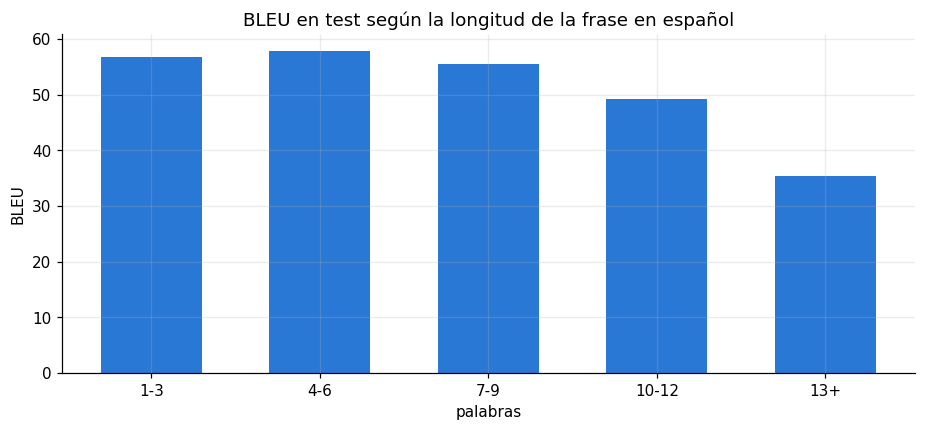

,frases,bleu
bucket,,
1-3,1133.0,56.83
4-6,3421.0,57.92
7-9,1807.0,55.52
10-12,646.0,49.15
13+,635.0,35.42


In [71]:
test = splits["test"].assign(words=lambda d: d["es"].str.split().str.len())
test["modelo"] = translator.translate(test["es"])
test["bucket"] = pd.cut(test["words"], bins=[0, 3, 6, 9, 12, 100], labels=["1-3", "4-6", "7-9", "10-12", "13+"])

by_length = test.groupby("bucket", observed=True)[["modelo", "en"]].apply(
    lambda g: pd.Series({"frases": len(g), "bleu": sacrebleu.corpus_bleu(g["modelo"].tolist(), [g["en"].tolist()]).score})
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_length.index.astype(str), by_length["bleu"], color=PALETTE[0], width=0.6)
ax.set(title="BLEU en test según la longitud de la frase en español", xlabel="palabras", ylabel="BLEU")
plt.show()
by_length.round(2)

### 9.3 Mapa de atención

Para una frase, se muestra a qué tokens en español mira cada token en inglés que genera el modelo (promedio de las cabezas en cada capa).

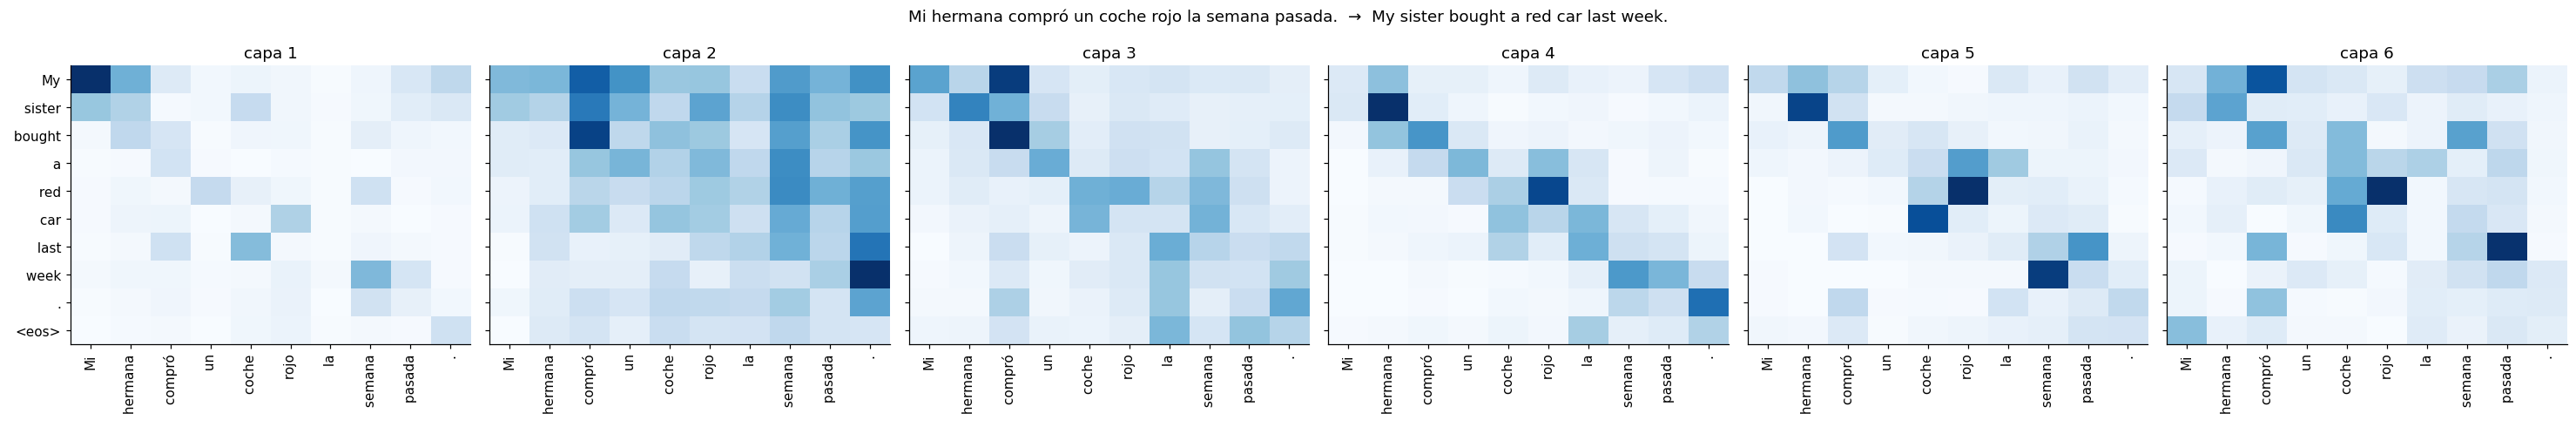

In [72]:
def plot_attention(sentence):
    model.eval()
    prompt = tokenizer.prompt(tokenizer.encode([sentence])[0])
    idx = torch.tensor([prompt], device=DEVICE)
    sequence = model.generate(idx, BLOCK_SIZE - len(prompt), tokenizer.eos_id)[0].tolist()
    attentions = [block.attn for block in model.transformer.h]
    for attn in attentions:
        attn.store_attention = True
    with torch.no_grad():
        model(torch.tensor([sequence[:-1]], device=DEVICE))
    for attn in attentions:
        attn.store_attention = False

    rows = range(len(prompt) - 1, len(sequence) - 1)
    cols = range(1, len(prompt) - 1)
    row_labels = tokenizer.pieces(sequence[len(prompt):])
    col_labels = tokenizer.pieces(sequence[1:len(prompt) - 1])

    fig, axes = plt.subplots(1, len(attentions), figsize=(4.5 * len(attentions), 4.5), squeeze=False)
    for layer, (ax, attn) in enumerate(zip(axes[0], attentions)):
        weights = attn.attention[0].mean(0).float().cpu().numpy()[np.ix_(rows, cols)]
        ax.imshow(weights, cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(col_labels)), col_labels, rotation=90)
        ax.set_yticks(range(len(row_labels)), row_labels if layer == 0 else [])
        ax.set_title(f"capa {layer + 1}")
        ax.grid(False)
    fig.suptitle(f"{sentence}  →  {tokenizer.decode(sequence[len(prompt):])}")
    fig.tight_layout()
    plt.show()


plot_attention("Mi hermana compró un coche rojo la semana pasada.")

### 9.4 Prueba con tus propias frases

In [73]:
my_sentences = [
    "Mañana voy a entrenar mi propio modelo de lenguaje.",
    "¿Me puedes ayudar a encontrar mis llaves?",
    "El perro de mi vecino ladra toda la noche.",
    "No tengo tiempo para ver películas esta semana.",
    "Ella siempre llega tarde a las reuniones del trabajo.",
    "Si llueve mañana, nos quedaremos en casa.",
    "Te amo Emily Guerrero.",
    "Barcelona es el mejor equipo del mundo."
]
pd.DataFrame({"español": my_sentences, "modelo": translator.translate(my_sentences)})

,español,modelo
0,Mañana voy a entrenar mi propio modelo de lenguaje.,Tomorrow I'm going to train my own language model.
1,¿Me puedes ayudar a encontrar mis llaves?,Can you help me find my keys?
2,El perro de mi vecino ladra toda la noche.,My neighbor's dog barks all night.
3,No tengo tiempo para ver películas esta semana.,I don't have time to watch movies this week.
4,Ella siempre llega tarde a las reuniones del trabajo.,She is always late for work meetings.
5,"Si llueve mañana, nos quedaremos en casa.","If it rains tomorrow, we'll stay home."
6,Te amo Emily Guerrero.,I love you Emily Guerrero.
7,Barcelona es el mejor equipo del mundo.,"Bargos, the world's best team."
